# 01 — Exploration des données

Dataset UCI *Estimation of Obesity Levels* (2 111 lignes, 17 colonnes). Objectif : comprendre les données **avant** toute modélisation et repérer les pièges (fuite, données synthétiques, doublons, modalités rares).

In [1]:
import pandas as pd
from IPython.display import display
from obesity import eda
from obesity.data import load_raw
df = load_raw()
display(df.head())
print(eda.diagnostics(df))
display(df.describe().T)

,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
0,Female,21.0,1.62,64.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,0.0,1.0,no,Public_Transportation,Normal_Weight
1,Female,21.0,1.52,56.0,yes,no,3.0,3.0,Sometimes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
2,Male,23.0,1.80,77.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,2.0,1.0,Frequently,Public_Transportation,Normal_Weight
3,Male,27.0,1.80,87.0,no,no,3.0,3.0,Sometimes,no,2.0,no,2.0,0.0,Frequently,Walking,Overweight_Level_I
4,Male,22.0,1.78,89.8,no,no,2.0,1.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II


{'shape': (2111, 17), 'dtypes': {'Gender': 'str', 'Age': 'float64', 'Height': 'float64', 'Weight': 'float64', 'family_history_with_overweight': 'str', 'FAVC': 'str', 'FCVC': 'float64', 'NCP': 'float64', 'CAEC': 'str', 'SMOKE': 'str', 'CH2O': 'float64', 'SCC': 'str', 'FAF': 'float64', 'TUE': 'float64', 'CALC': 'str', 'MTRANS': 'str', 'NObeyesdad': 'str'}, 'nan': 0, 'duplicates': 24}


,count,mean,std,min,25%,50%,75%,max
Age,2111.0,24.312600,6.345968,14.00,19.947192,22.777890,26.000000,61.00
Height,2111.0,1.701677,0.093305,1.45,1.630000,1.700499,1.768464,1.98
Weight,2111.0,86.586058,26.191172,39.00,65.473343,83.000000,107.430682,173.00
FCVC,2111.0,2.419043,0.533927,1.00,2.000000,2.385502,3.000000,3.00
NCP,2111.0,2.685628,0.778039,1.00,2.658738,3.000000,3.000000,4.00
CH2O,2111.0,2.008011,0.612953,1.00,1.584812,2.000000,2.477420,3.00
FAF,2111.0,1.010298,0.850592,0.00,0.124505,1.000000,1.666678,3.00
TUE,2111.0,0.657866,0.608927,0.00,0.000000,0.625350,1.000000,2.00


## Diagnostic
Aucune valeur manquante. On compte **24 doublons**, supprimés avant le split afin qu'une même ligne ne se retrouve pas à la fois dans le train et le test.

In [2]:
df = df.drop_duplicates()
from obesity import config as cfg
num = ['Age','Height','Weight'] + cfg.load_config()['columns']['numeric'][1:]
display(eda.class_stats(df, ['Age','Weight','Height']).round(2))
display(eda.iqr_outliers(df, num).to_frame('outliers_IQR'))

Age               Weight                Height         \
                      mean median   std    mean  median    std   mean median   
NObeyesdad                                                                     
Insufficient_Weight  19.77  19.21  2.69   50.01   50.00   5.99   1.69   1.70   
Normal_Weight        21.76  21.00  5.12   62.16   61.00   9.32   1.68   1.66   
Obesity_Type_I       25.88  22.98  7.76   92.87   90.74  11.49   1.69   1.68   
Obesity_Type_II      28.23  27.19  4.87  115.31  117.79   8.02   1.77   1.77   
Obesity_Type_III     23.50  25.37  2.76  120.94  112.05  15.53   1.69   1.67   
Overweight_Level_I   23.54  21.31  6.25   74.48   75.00   8.63   1.69   1.70   
Overweight_Level_II  27.00  24.00  8.06   82.09   82.00   8.45   1.70   1.70   

                           
                      std  
NObeyesdad                 
Insufficient_Weight  0.10  
Normal_Weight        0.10  
Obesity_Type_I       0.10  
Obesity_Type_II      0.07  
Obesity_Type_III     0.07  
Overweight_Level_I   0.10  
Overweight_Level_II  0.09

,outliers_IQR
Age,167
Height,1
Weight,1
FCVC,0
NCP,577
CH2O,0
FAF,0
TUE,0


## Statistiques par classe et outliers
Les statistiques par classe confirment que `Weight` sépare presque parfaitement les classes. Les outliers (règle IQR) sont peu nombreux et plausibles ; on les conserve.

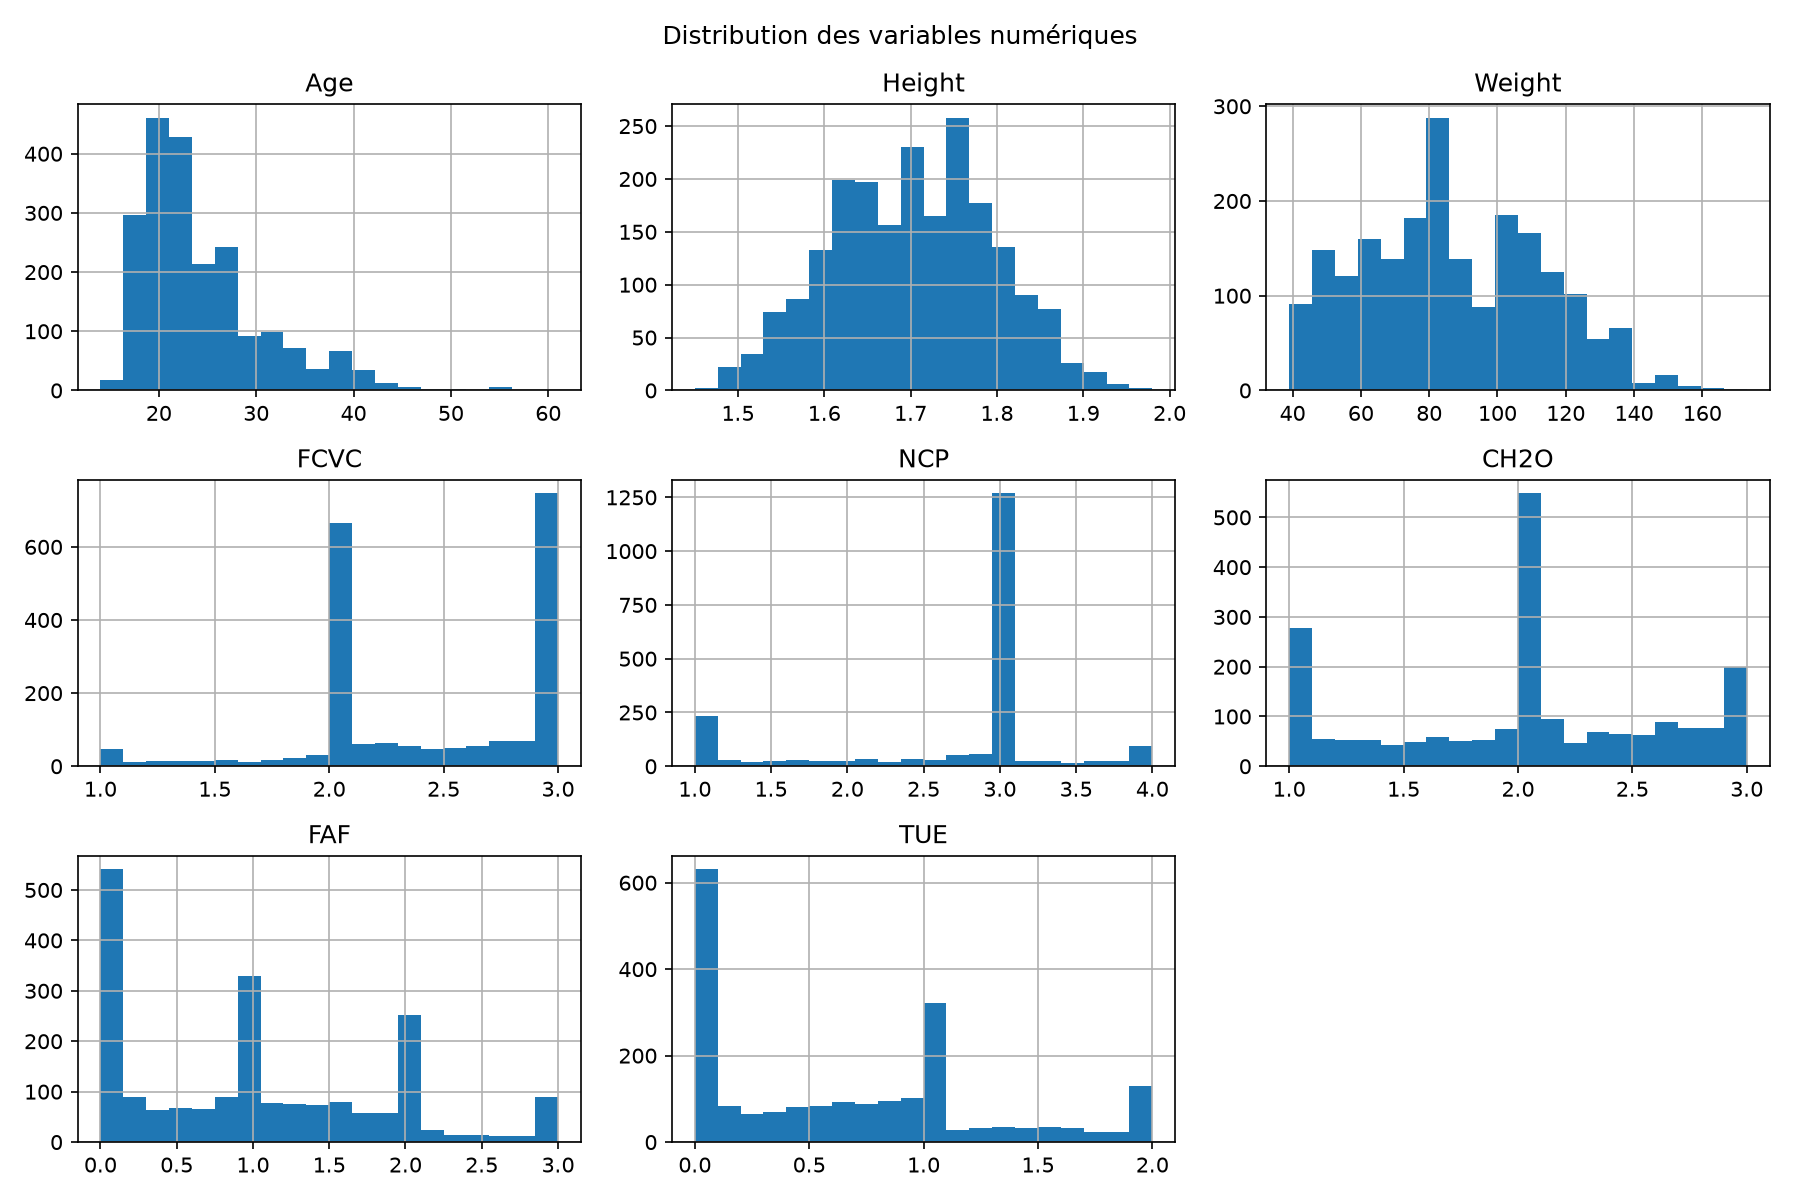

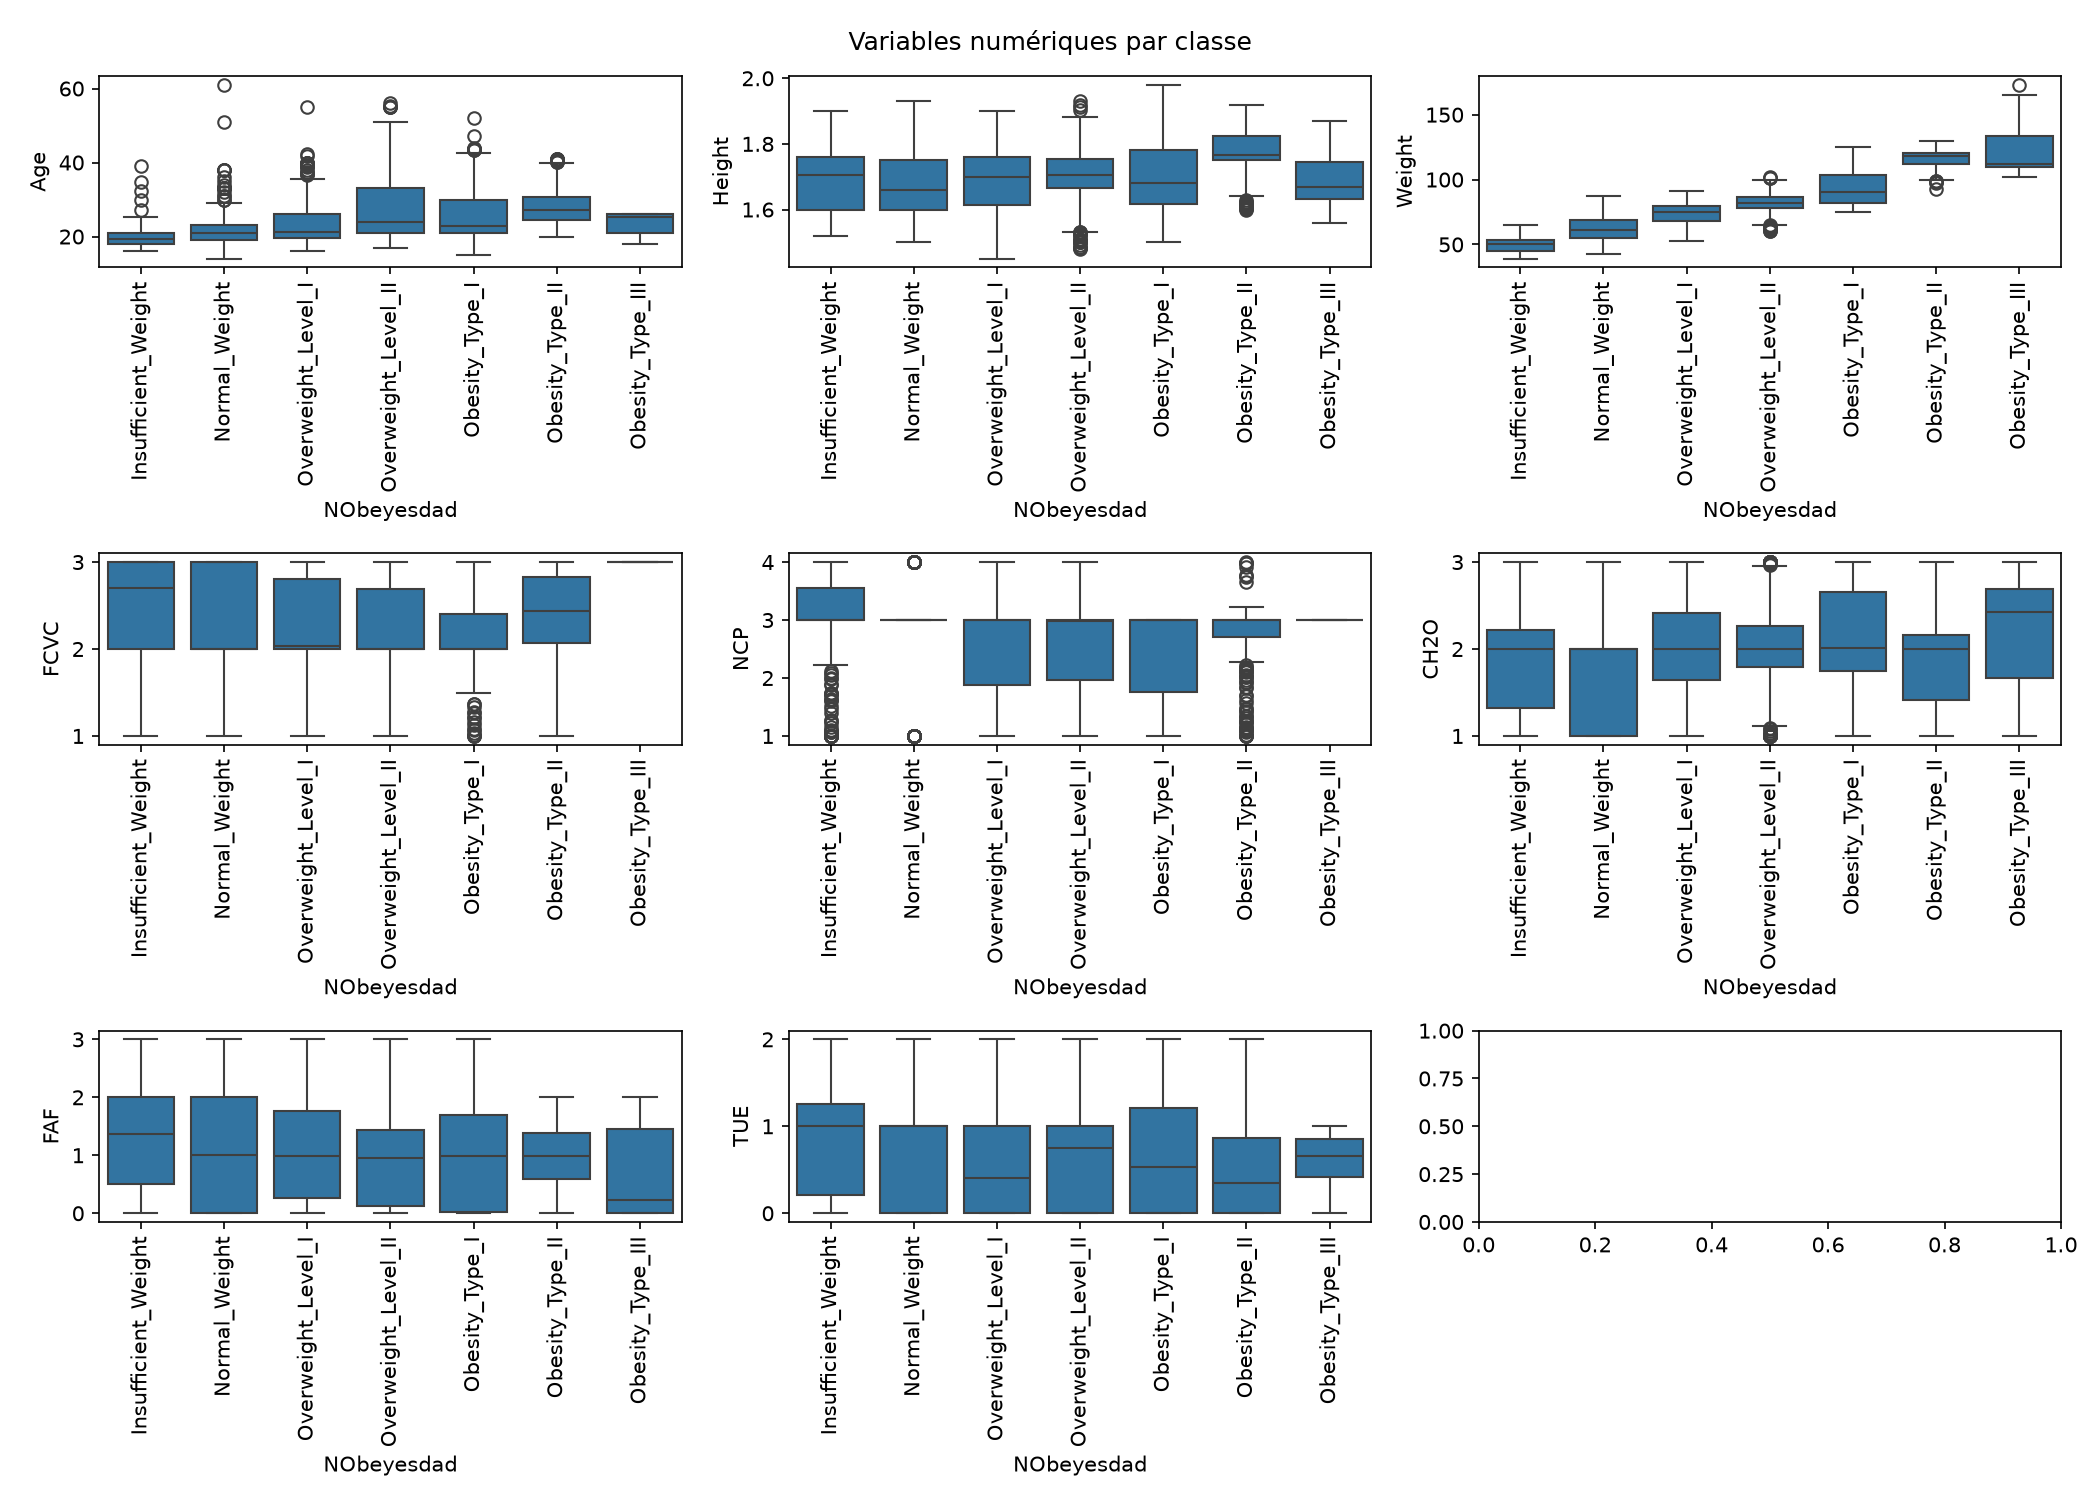

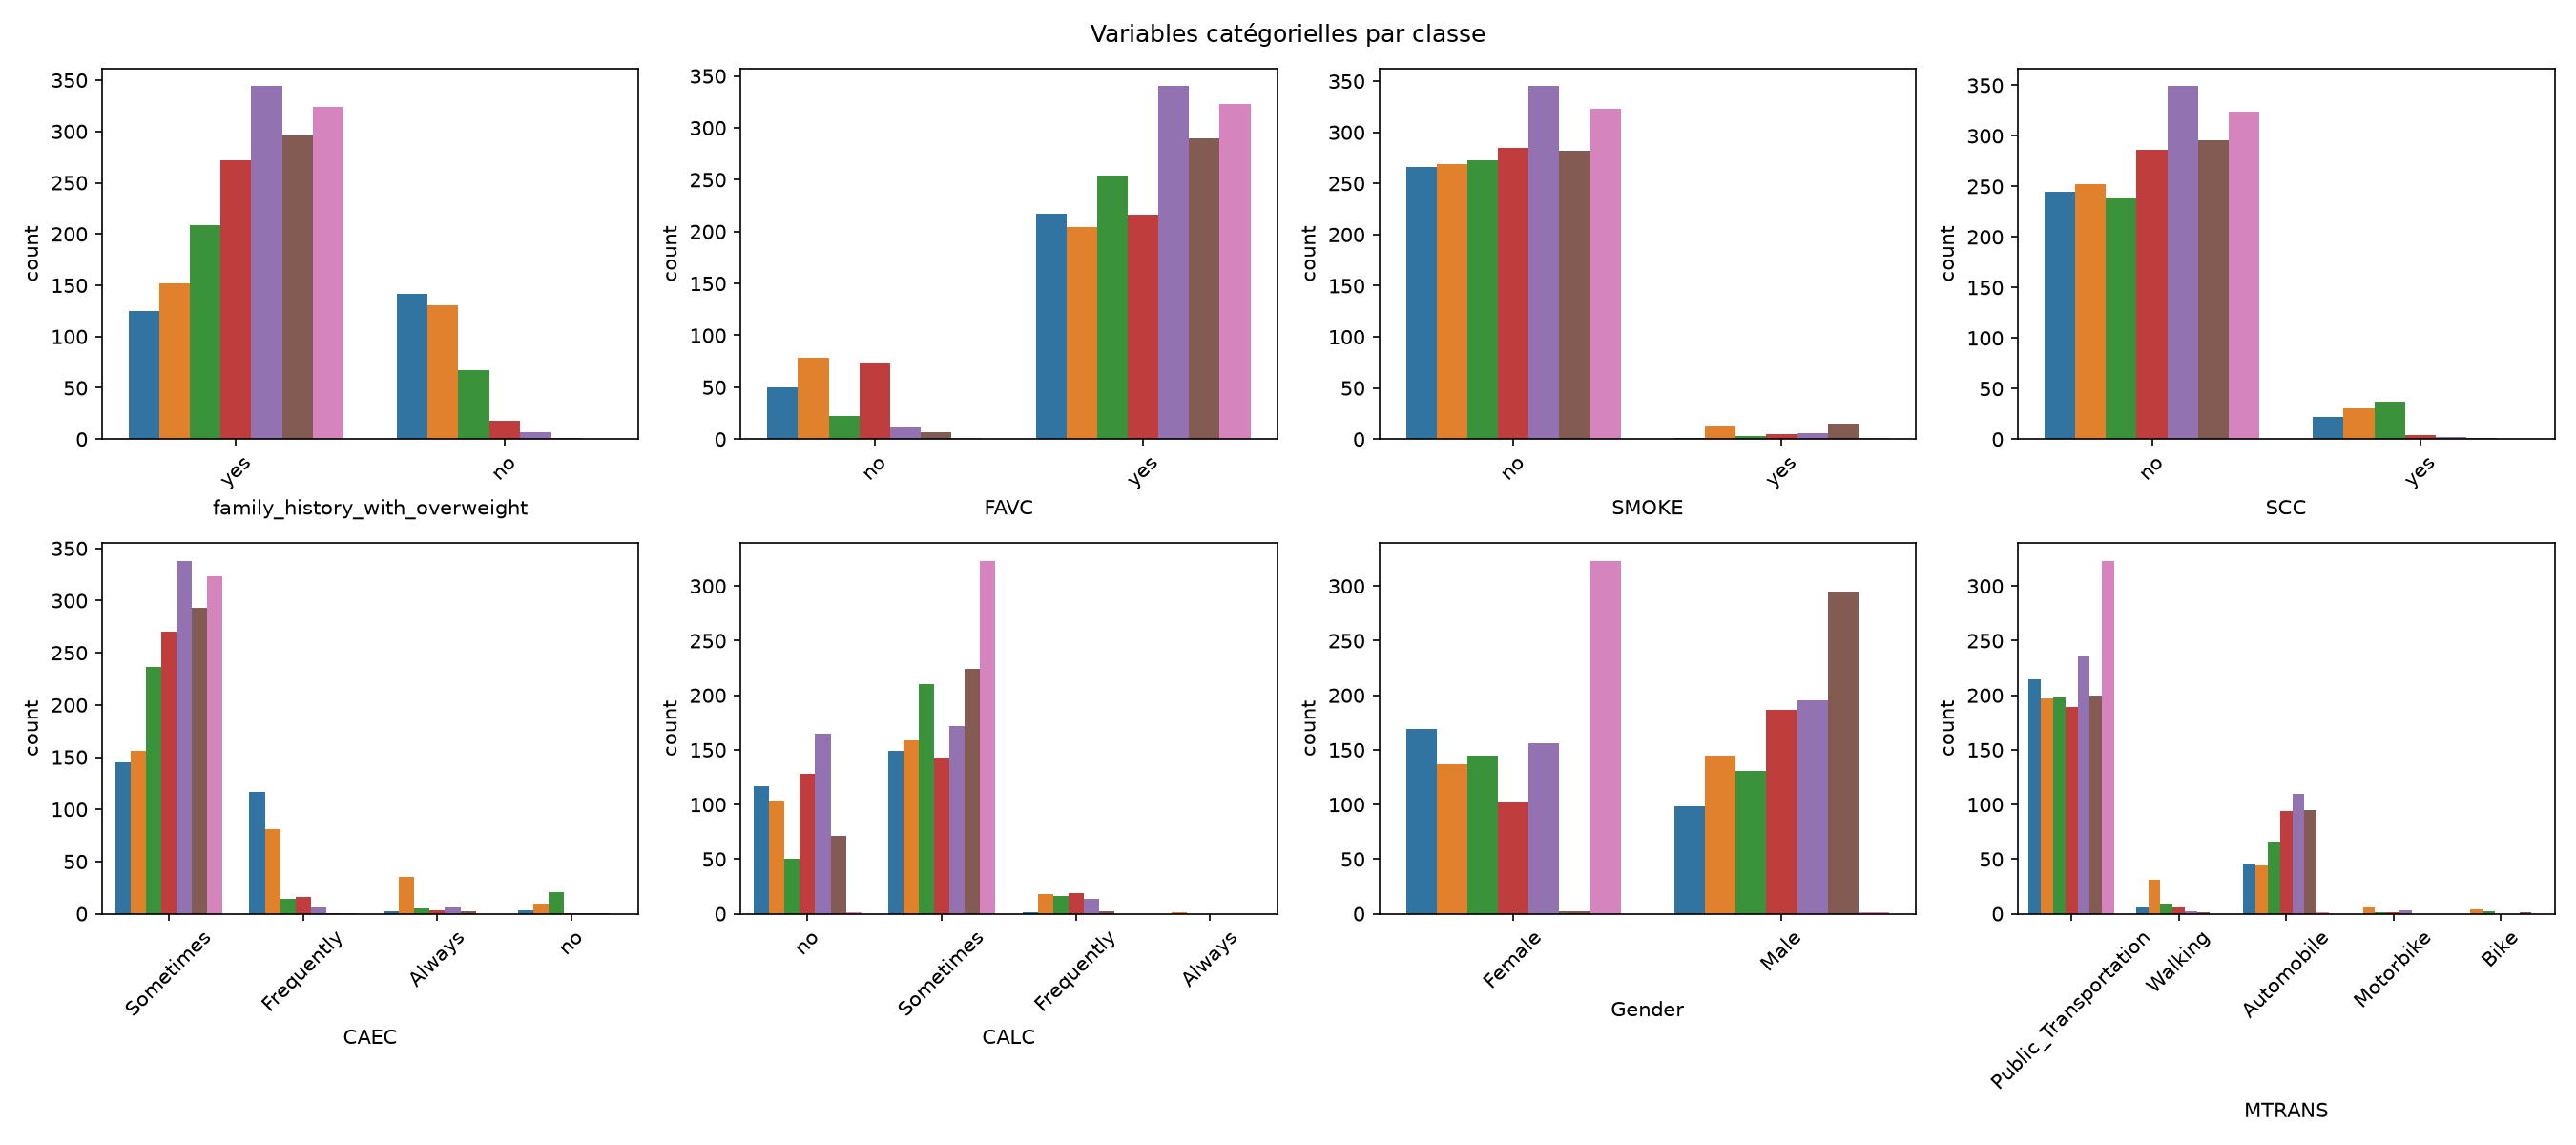

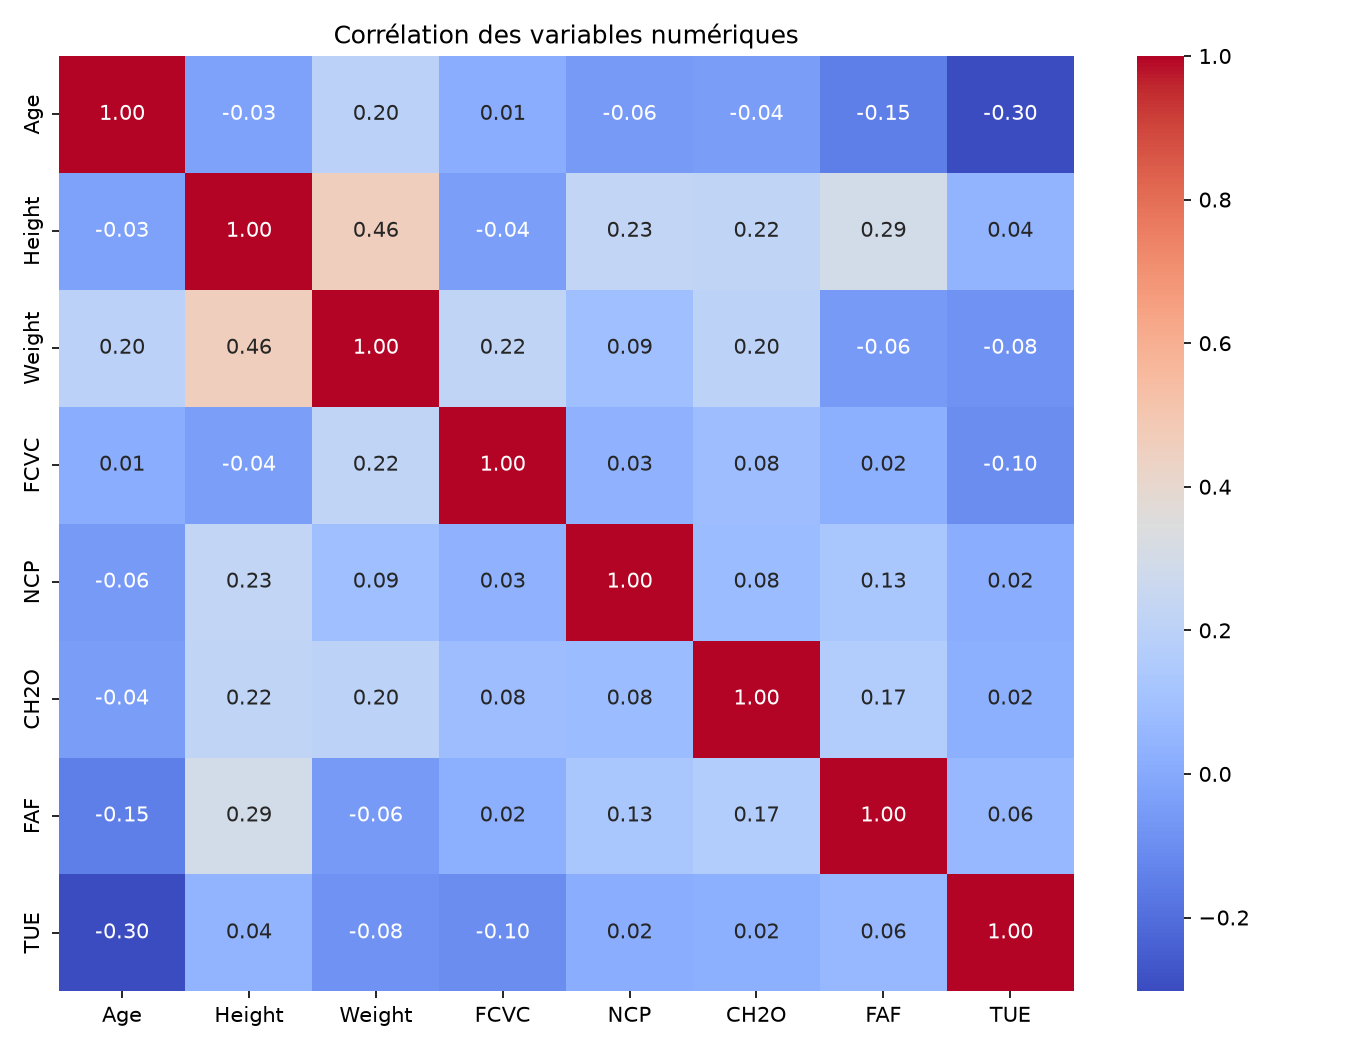

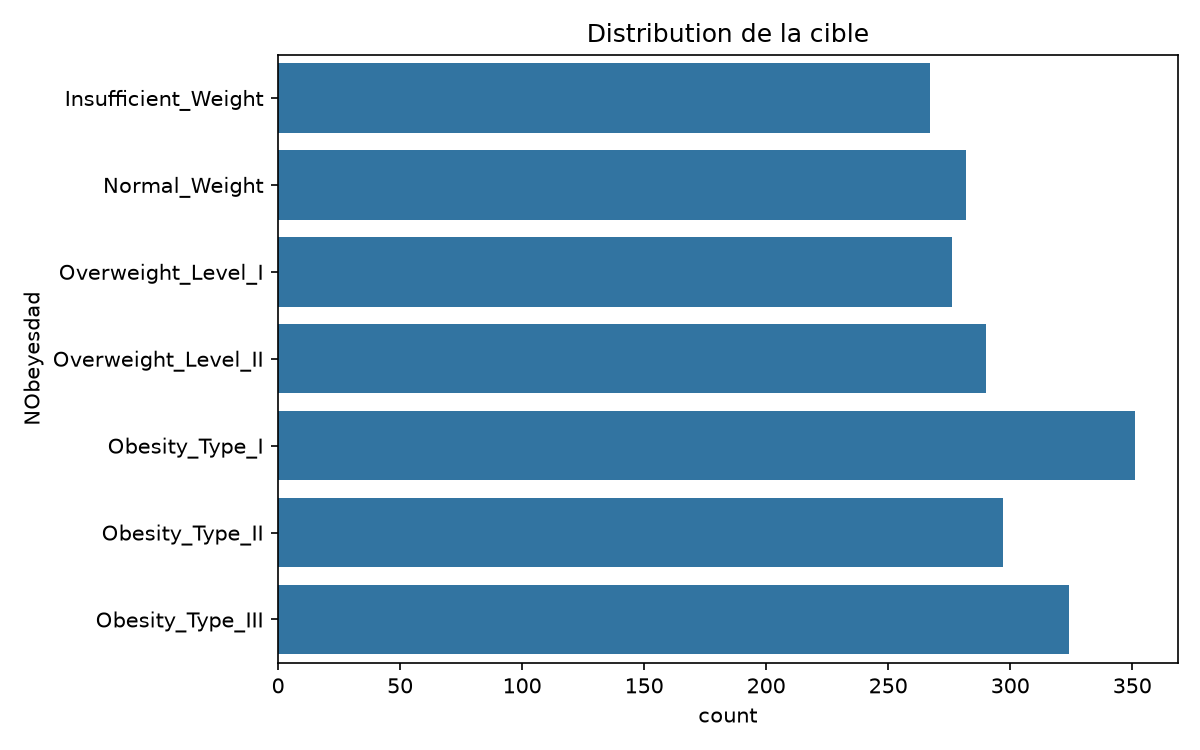

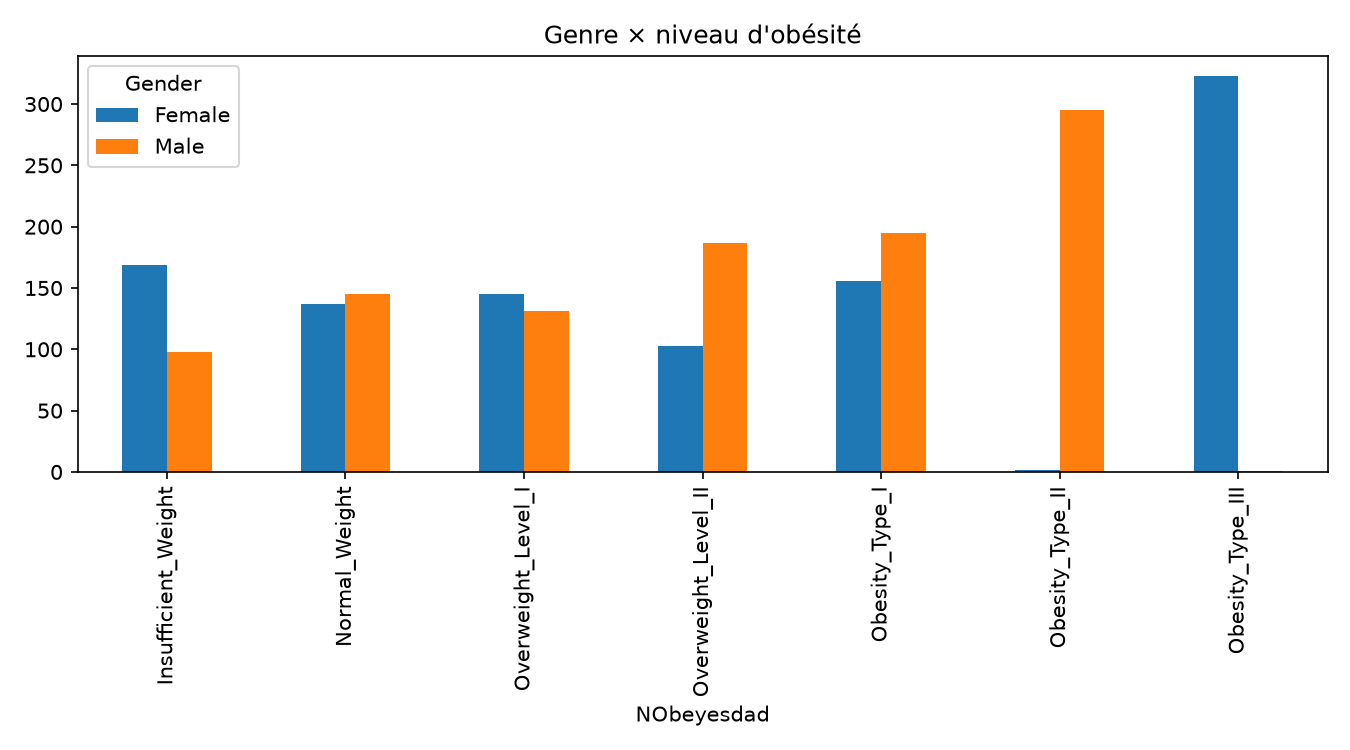

In [3]:
eda.make_figures(df)
from IPython.display import Image
for f in ['hist_numeriques','boxplots_par_classe','countplots_categorielles','correlation','cible','genre_x_classe']:
    display(Image(str(cfg.path('figures_dir') / f'eda_{f}.png'), width=800))

## Fuite de données
La classe est **dérivée de l'IMC** = Weight / Height². Le tableau ci-dessous montre les bornes d'IMC observées par classe : donner `Weight` et `Height` au classifieur revient à lui donner la réponse. Les pipelines de classification les excluent.

In [4]:
display(eda.bmi_by_class(df).round(2))

,min,max
NObeyesdad,,
Insufficient_Weight,13.00,19.08
Normal_Weight,18.49,24.91
Overweight_Level_I,22.83,28.77
Overweight_Level_II,25.71,30.36
Obesity_Type_I,29.91,35.17
Obesity_Type_II,34.05,39.79
Obesity_Type_III,36.77,50.81


## Données synthétiques (heuristique)
~77 % des lignes sont générées par SMOTE. Proxy : au moins une variable ordinale (FCVC, NCP, CH2O, FAF, TUE) non entière avant arrondi. **C'est une heuristique**, pas une vérité.

In [5]:
print('Part de lignes proxy-synthétiques :', round(eda.synthetic_proxy(df).mean(), 3))
display(pd.crosstab(df['Gender'], df['NObeyesdad']))

Part de lignes proxy-synthétiques : 0.757


NObeyesdad,Insufficient_Weight,Normal_Weight,Obesity_Type_I,Obesity_Type_II,Obesity_Type_III,Overweight_Level_I,Overweight_Level_II
Gender,,,,,,,
Female,169,137,156,2,323,145,103
Male,98,145,195,295,1,131,187


## Biais de genre
`Obesity_Type_II` est quasi exclusivement masculin et `Obesity_Type_III` quasi exclusivement féminin. Ce biais est un artefact de la construction du jeu de données ; il est **mesuré et discuté** (notebook 04), pas corrigé silencieusement.